In [22]:
import numpy as np
import pandas as pd
import skfuzzy as fuzz
import matplotlib.pyplot as plt 

In [14]:
file_path = "dataset_kepribadian_mahasiswa.xlsx"  # Ganti sesuai file excel input kamu

In [ ]:
# Domain input dan output
x = np.arange(0, 151, 1)  # input [0-150]
z = np.arange(0, 101, 1)  # output [0-100]

# Himpunan fuzzy untuk input
tidak_yakin = fuzz.trimf(x, [0, 0, 75])
ragu = fuzz.trimf(x, [25, 75, 125])
yakin = fuzz.trimf(x, [75, 150, 150])

# Himpunan fuzzy untuk output kepribadian (5 level)
sangat_rendah = fuzz.trimf(z, [0, 20, 30])
rendah = fuzz.trimf(z, [20, 35, 50])
sedang = fuzz.trimf(z, [40, 55, 65])
tinggi = fuzz.trimf(z, [60, 70, 80])
sangat_tinggi = fuzz.trimf(z, [75, 90, 100])

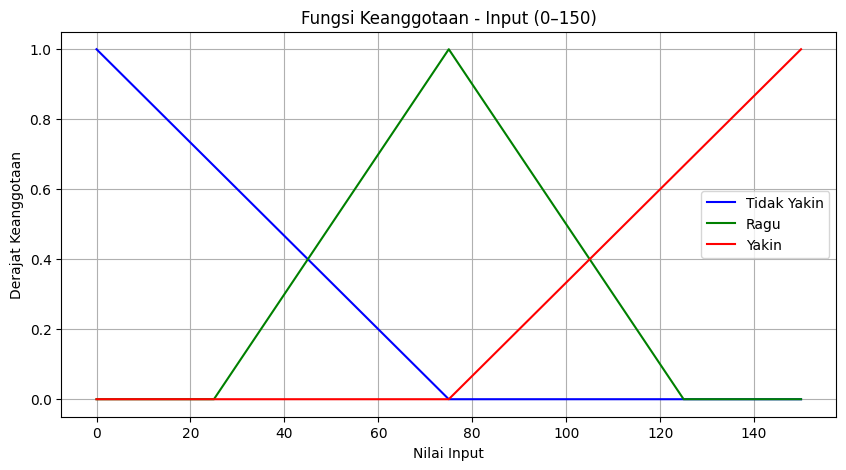

In [23]:
# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, tidak_yakin, 'b', label='Tidak Yakin')
plt.plot(x, ragu, 'g', label='Ragu')
plt.plot(x, yakin, 'r', label='Yakin')
plt.title('Fungsi Keanggotaan - Input (0–150)')
plt.xlabel('Nilai Input')
plt.ylabel('Derajat Keanggotaan')
plt.legend()
plt.grid(True)
plt.show()

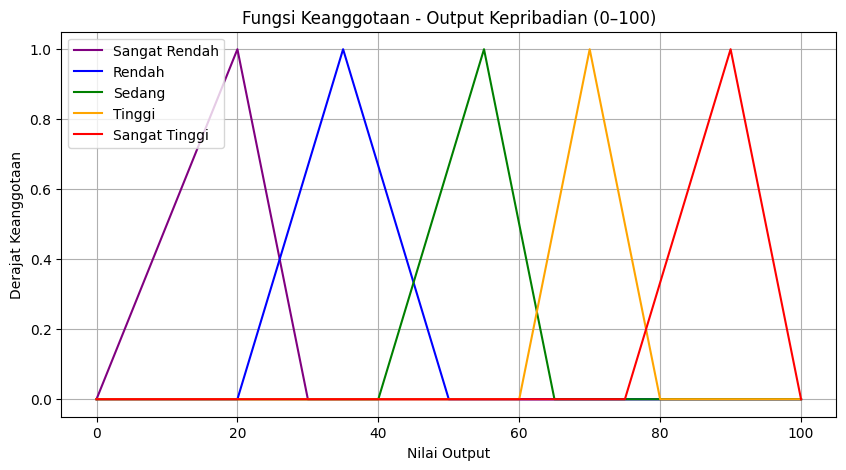

In [24]:
# Plot
plt.figure(figsize=(10, 5))
plt.plot(z, sangat_rendah, 'purple', label='Sangat Rendah')
plt.plot(z, rendah, 'blue', label='Rendah')
plt.plot(z, sedang, 'green', label='Sedang')
plt.plot(z, tinggi, 'orange', label='Tinggi')
plt.plot(z, sangat_tinggi, 'red', label='Sangat Tinggi')
plt.title('Fungsi Keanggotaan - Output Kepribadian (0–100)')
plt.xlabel('Nilai Output')
plt.ylabel('Derajat Keanggotaan')
plt.legend()
plt.grid(True)

In [4]:
# Fungsi keanggotaan input
def get_membership(value):
    return {
        "Tidak Yakin": fuzz.interp_membership(x, tidak_yakin, value),
        "Ragu": fuzz.interp_membership(x, ragu, value),
        "Yakin": fuzz.interp_membership(x, yakin, value)
    }

In [5]:
kepribadian = {
    "Sanguinis": ["Keyakinan", "Keramahan", "Keberanian"],
    "Koleris": ["Emosi", "Visioner", "Penolong"],
    "Melankolis": ["Skeptis", "Bimbang", "Ego Sentrik"],
    "Plegmatis": ["Kerajinan", "Kepekaan", "Mudah Bosan"]
}

In [6]:
# Definisi level input fuzzy dan output fuzzy
input_levels = {0: "Tidak Yakin", 1: "Ragu", 2: "Yakin"}
output_levels = {0: "Sangat Rendah", 1: "Rendah", 2: "Sedang", 3: "Tinggi", 4: "Sangat Tinggi"}

# Tsukamoto

In [7]:
# Mapping level input minimal ke level output (untuk rule)
def map_output_level(min_level_input):
    # Biar lebih lengkap, kita buat mapping linear antara level minimal input dan output
    # Input min: 0 → Sangat Rendah (0)
    # Input min: 1 → Sedang (2)
    # Input min: 2 → Sangat Tinggi (4)
    if min_level_input == 0:
        return 0  # Sangat Rendah
    elif min_level_input == 1:
        return 2  # Sedang
    elif min_level_input == 2:
        return 4  # Sangat Tinggi
    else:
        return 2  # Default ke Sedang

In [8]:
# Fungsi defuzzifikasi Tsukamoto-style
def tsukamoto_defuzz(alpha, tipe):
    if alpha == 0:
        return 0, 0  # Tidak berkontribusi
    if tipe == "Sangat Rendah":
        z_val = fuzz.defuzz(z, sangat_rendah, 'centroid')
    elif tipe == "Rendah":
        z_val = fuzz.defuzz(z, rendah, 'centroid')
    elif tipe == "Sedang":
        z_val = fuzz.defuzz(z, sedang, 'centroid')
    elif tipe == "Tinggi":
        z_val = fuzz.defuzz(z, tinggi, 'centroid')
    else:  # Sangat Tinggi
        z_val = fuzz.defuzz(z, sangat_tinggi, 'centroid')
    return alpha * z_val, alpha

In [9]:
# Fungsi mengevaluasi satu baris data dengan semua rule 108 aturan
def evaluate_row(row):
    hasil = {}
    for tipe, ciri_list in kepribadian.items():
        memberships = [get_membership(row[ciri]) for ciri in ciri_list]
        # memberships = [{'Tidak Yakin':..,'Ragu':..,'Yakin':..}, ...] untuk 3 ciri

        total_num = 0
        total_den = 0
        matched_rule = False

        # Iterasi semua kombinasi level input (0=Tidak Yakin,1=Ragu,2=Yakin)
        for lvl1 in range(3):
            for lvl2 in range(3):
                for lvl3 in range(3):
                    # Dapatkan derajat keanggotaan tiap ciri sesuai level
                    mu1 = memberships[0][input_levels[lvl1]]
                    mu2 = memberships[1][input_levels[lvl2]]
                    mu3 = memberships[2][input_levels[lvl3]]

                    # Aktivasi rule = min dari keanggotaan (AND fuzzy)
                    alpha = min(mu1, mu2, mu3)

                    if alpha > 0:
                        matched_rule = True
                        min_lvl = min(lvl1, lvl2, lvl3)
                        out_lvl_index = map_output_level(min_lvl)
                        out_label = output_levels[out_lvl_index]

                        num, den = tsukamoto_defuzz(alpha, out_label)
                        total_num += num
                        total_den += den

        # Jika total_den 0 berarti semua alpha=0, beri nilai default (nilai 'Sedang')
        if total_den == 0:
            total_num = fuzz.defuzz(z, sedang, 'centroid')
            total_den = 1

        hasil[tipe] = total_num / total_den

    tipe_tertinggi = max(hasil, key=hasil.get)

    return hasil, tipe_tertinggi

In [10]:
def proses_data(filename):
    df = pd.read_excel(filename)

    list_z = []
    list_tipe = []

    for _, row in df.iterrows():
        z_vals, tipe = evaluate_row(row)
        list_z.append(z_vals)
        list_tipe.append(tipe)

    hasil_df = pd.DataFrame(list_z)
    hasil_df["Tipe Kepribadian"] = list_tipe

    total_data = len(list_tipe)
    valid_tipe_list = [t for t in list_tipe if t != "Kepribadian Tidak Sesuai Rulebase"]
    valid_count = len(valid_tipe_list)
    invalid_count = total_data - valid_count
    valid_percent = valid_count / total_data * 100
    invalid_percent = invalid_count / total_data * 100

    from collections import Counter
    tipe_counter = Counter(valid_tipe_list)

    if tipe_counter:
        tipe_tertinggi = tipe_counter.most_common(1)[0]
        tipe_terendah = tipe_counter.most_common()[-1]
        tertinggi_label, tertinggi_count = tipe_tertinggi
        terendah_label, terendah_count = tipe_terendah
        tertinggi_percent = tertinggi_count / total_data * 100
        terendah_percent = terendah_count / total_data * 100
    else:
        tertinggi_label = terendah_label = "N/A"
        tertinggi_percent = terendah_percent = 0

    print(f"Total data: {total_data}")
    print(f"Valid kepribadian terdeteksi: {valid_count} ({valid_percent:.2f}%)")
    print(f"Kepribadian tidak sesuai rulebase: {invalid_count} ({invalid_percent:.2f}%)")
    print(f"Kepribadian tertinggi: {tertinggi_label} sebanyak {tertinggi_count} data ({tertinggi_percent:.2f}%)")
    print(f"Kepribadian terendah: {terendah_label} sebanyak {terendah_count} data ({terendah_percent:.2f}%)")
    print("\nPersentase masing-masing kepribadian (yang valid):")
    for tipe, count in tipe_counter.items():
        percent = count / total_data * 100
        print(f"- {tipe}: {count} data ({percent:.2f}%)")

    final_df = pd.concat([df, hasil_df], axis=1)
    return final_df

In [21]:
hasil = proses_data(file_path)

# Simpan hasil ke file output
hasil.to_excel("ooutput.xlsx", index=False)
hasil.head(50)

Total data: 50
Valid kepribadian terdeteksi: 50 (100.00%)
Kepribadian tidak sesuai rulebase: 0 (0.00%)
Kepribadian tertinggi: Sanguinis sebanyak 14 data (28.00%)
Kepribadian terendah: Melankolis sebanyak 10 data (20.00%)

Persentase masing-masing kepribadian (yang valid):
- Sanguinis: 14 data (28.00%)
- Melankolis: 10 data (20.00%)
- Koleris: 14 data (28.00%)
- Plegmatis: 12 data (24.00%)


,Keyakinan,Keramahan,Keberanian,Emosi,Visioner,Penolong,Skeptis,Bimbang,Ego Sentrik,Kerajinan,Kepekaan,Mudah Bosan,Sanguinis,Koleris,Melankolis,Plegmatis,Tipe Kepribadian
0,120,150,90,120,150,90,60,30,90,150,120,60,60.333333,60.333333,21.250000,42.333333,Sanguinis
1,90,120,150,60,120,150,90,60,30,120,150,90,60.333333,42.333333,21.250000,60.333333,Sanguinis
2,150,90,120,150,90,120,150,90,60,30,120,150,60.333333,60.333333,42.051282,24.814815,Sanguinis
3,60,30,150,90,60,30,120,150,90,60,30,120,20.333333,21.250000,60.333333,21.904762,Melankolis
4,30,60,90,120,150,60,30,120,150,90,60,30,21.250000,42.333333,24.814815,21.250000,Koleris
5,120,90,60,30,120,150,90,60,30,120,150,90,39.583333,24.814815,21.250000,60.333333,Plegmatis
6,90,60,30,150,90,60,30,120,150,90,60,30,21.250000,42.051282,24.814815,21.250000,Koleris
7,150,120,90,60,30,120,150,90,60,30,120,150,60.333333,21.904762,42.051282,24.814815,Sanguinis
8,60,90,120,150,60,30,120,150,90,60,30,120,39.583333,20.333333,60.333333,21.904762,Melankolis
9,30,120,150,90,30,60,90,120,150,60,90,120,24.814815,21.250000,60.333333,39.583333,Melankolis


# Sugeno

1. DATA CHARACTERISTICS:
   - Range: 30-150
   - Nilai unik: 30, 60, 90, 120, 150 (pola incremental 30)
   - Distribusi: Relatif merata

2. PARAMETER UNTUK SUGENO:
   BERDASARKAN DOMAIN KNOWLEDGE, RANGE DAN DISTRIBUSI. DIDAPAT NILAI PARAMETER

   KONSTANTA:
   - Sangat Rendah: 20
   - Rendah: 35  
   - Sedang: 50
   - Tinggi: 70
   - Sangat Tinggi: 85

   LINEAR:
   - Sangat Rendah: z = 0.05*x1 + 0.05*x2 + 0.05*x3 + 10
   - Rendah: z = 0.10*x1 + 0.10*x2 + 0.10*x3 + 15
   - Sedang: z = 0.15*x1 + 0.15*x2 + 0.15*x3 + 20
   - Tinggi: z = 0.20*x1 + 0.20*x2 + 0.20*x3 + 25
   - Sangat Tinggi: z = 0.25*x1 + 0.25*x2 + 0.25*x3 + 30

In [47]:
# Definisi fungsi konsekuen Sugeno (linear/konstanta)
# Untuk setiap level output, kita definisikan fungsi linear: z = a*x1 + b*x2 + c*x3 + d
# Atau bisa menggunakan konstanta sederhana untuk masing-masing level

def get_sugeno_consequent_constants():
    return {
        "Sangat Rendah": {"constant": 20, "linear": [0.05, 0.05, 0.05, 10]},
        "Rendah": {"constant": 35, "linear": [0.10, 0.10, 0.10, 15]},
        "Sedang": {"constant": 50, "linear": [0.15, 0.15, 0.15, 20]},
        "Tinggi": {"constant": 70, "linear": [0.20, 0.20, 0.20, 25]},
        "Sangat Tinggi": {"constant": 85, "linear": [0.25, 0.25, 0.25, 30]}
    }

In [ ]:
def sugeno_consequent_value(input_values, output_level, method="constant"):
    constants = get_sugeno_consequent_constants()
    
    if method == "constant":
        return constants[output_level]["constant"]
    elif method == "linear":
        coeffs = constants[output_level]["linear"]
        # z = a*x1 + b*x2 + c*x3 + d
        return (coeffs[0] * input_values[0] + 
                coeffs[1] * input_values[1] + 
                coeffs[2] * input_values[2] + 
                coeffs[3])
    else:
        return constants[output_level]["constant"]

def sugeno_defuzzification(rules_output, method="constant"):
    total_weighted = 0
    total_weights = 0
    
    for alpha, z_val in rules_output:
        if alpha > 0:
            total_weighted += alpha * z_val
            total_weights += alpha
    
    if total_weights == 0:
        return 50  # Nilai default jika tidak ada rule yang aktif
    
    return total_weighted / total_weights

In [48]:
def evaluate_row_sugeno(row, method="constant"):
    hasil = {}
    
    for tipe, ciri_list in kepribadian.items():
        memberships = [get_membership(row[ciri]) for ciri in ciri_list]
        input_values = [row[ciri] for ciri in ciri_list]
        
        rules_output = []
        
        # Iterasi semua kombinasi level input
        for lvl1 in range(3):
            for lvl2 in range(3):
                for lvl3 in range(3):
                    # Dapatkan derajat keanggotaan
                    mu1 = memberships[0][input_levels[lvl1]]
                    mu2 = memberships[1][input_levels[lvl2]]
                    mu3 = memberships[2][input_levels[lvl3]]
                    
                    # Aktivasi rule (AND fuzzy)
                    alpha = min(mu1, mu2, mu3)
                    
                    if alpha > 0:
                        # Tentukan level output berdasarkan level input minimal
                        min_lvl = min(lvl1, lvl2, lvl3)
                        out_lvl_index = map_output_level(min_lvl)
                        out_label = output_levels[out_lvl_index]
                        
                        # Hitung nilai konsekuen Sugeno
                        z_val = sugeno_consequent_value(input_values, out_label, method)
                        rules_output.append((alpha, z_val))
        
        # Defuzzifikasi Sugeno
        hasil[tipe] = sugeno_defuzzification(rules_output, method)
    
    tipe_tertinggi = max(hasil, key=hasil.get)
    return hasil, tipe_tertinggi

def proses_data_sugeno(filename, method="constant"):
    df = pd.read_excel(filename)
    
    list_z = []
    list_tipe = []
    
    print(f"Memproses data dengan metode Sugeno ({method})...")
    
    for _, row in df.iterrows():
        z_vals, tipe = evaluate_row_sugeno(row, method)
        list_z.append(z_vals)
        list_tipe.append(tipe)
    
    hasil_df = pd.DataFrame(list_z)
    hasil_df["Tipe Kepribadian"] = list_tipe
    
    # Statistik hasil
    total_data = len(list_tipe)
    valid_tipe_list = [t for t in list_tipe if t != "Kepribadian Tidak Sesuai Rulebase"]
    valid_count = len(valid_tipe_list)
    invalid_count = total_data - valid_count
    valid_percent = valid_count / total_data * 100
    invalid_percent = invalid_count / total_data * 100
    
    from collections import Counter
    tipe_counter = Counter(valid_tipe_list)
    
    if tipe_counter:
        tipe_tertinggi = tipe_counter.most_common(1)[0]
        tipe_terendah = tipe_counter.most_common()[-1]
        tertinggi_label, tertinggi_count = tipe_tertinggi
        terendah_label, terendah_count = tipe_terendah
        tertinggi_percent = tertinggi_count / total_data * 100
        terendah_percent = terendah_count / total_data * 100
    else:
        tertinggi_label = terendah_label = "N/A"
        tertinggi_percent = terendah_percent = 0
    
    print(f"\n=== HASIL ANALISIS SUGENO ({method.upper()}) ===")
    print(f"Total data: {total_data}")
    print(f"Valid kepribadian terdeteksi: {valid_count} ({valid_percent:.2f}%)")
    print(f"Kepribadian tidak sesuai rulebase: {invalid_count} ({invalid_percent:.2f}%)")
    print(f"Kepribadian tertinggi: {tertinggi_label} sebanyak {tertinggi_count} data ({tertinggi_percent:.2f}%)")
    print(f"Kepribadian terendah: {terendah_label} sebanyak {terendah_count} data ({terendah_percent:.2f}%)")
    print("\nPersentase masing-masing kepribadian (yang valid):")
    for tipe, count in tipe_counter.items():
        percent = count / total_data * 100
        print(f"- {tipe}: {count} data ({percent:.2f}%)")
    
    final_df = pd.concat([df, hasil_df], axis=1)
    return final_df


hasil_sugeno_const = proses_data_sugeno(file_path, "constant")
hasil_sugeno_linear = proses_data_sugeno(file_path, "linear")
# Simpan hasil
hasil_sugeno_const.to_excel("hasil_sugeno_constant.xlsx", index=False)
hasil_sugeno_linear.to_excel("hasil_sugeno_linear.xlsx", index=False)

Memproses data dengan metode Sugeno (constant)...

=== HASIL ANALISIS SUGENO (CONSTANT) ===
Total data: 50
Valid kepribadian terdeteksi: 50 (100.00%)
Kepribadian tidak sesuai rulebase: 0 (0.00%)
Kepribadian tertinggi: Sanguinis sebanyak 14 data (28.00%)
Kepribadian terendah: Melankolis sebanyak 10 data (20.00%)

Persentase masing-masing kepribadian (yang valid):
- Sanguinis: 14 data (28.00%)
- Melankolis: 10 data (20.00%)
- Koleris: 14 data (28.00%)
- Plegmatis: 12 data (24.00%)
Memproses data dengan metode Sugeno (linear)...

=== HASIL ANALISIS SUGENO (LINEAR) ===
Total data: 50
Valid kepribadian terdeteksi: 50 (100.00%)
Kepribadian tidak sesuai rulebase: 0 (0.00%)
Kepribadian tertinggi: Koleris sebanyak 14 data (28.00%)
Kepribadian terendah: Melankolis sebanyak 10 data (20.00%)

Persentase masing-masing kepribadian (yang valid):
- Sanguinis: 13 data (26.00%)
- Plegmatis: 13 data (26.00%)
- Melankolis: 10 data (20.00%)
- Koleris: 14 data (28.00%)


In [49]:
hasil_sugeno_const.head(50)

,Keyakinan,Keramahan,Keberanian,Emosi,Visioner,Penolong,Skeptis,Bimbang,Ego Sentrik,Kerajinan,Kepekaan,Mudah Bosan,Sanguinis,Koleris,Melankolis,Plegmatis,Tipe Kepribadian
0,120,150,90,120,150,90,60,30,90,150,120,60,57.000000,57.000000,23.750000,41.000000,Sanguinis
1,90,120,150,60,120,150,90,60,30,120,150,90,57.000000,41.000000,23.750000,57.000000,Sanguinis
2,150,90,120,150,90,120,150,90,60,30,120,150,57.000000,57.000000,40.769231,26.666667,Sanguinis
3,60,30,150,90,60,30,120,150,90,60,30,120,23.000000,23.750000,57.000000,24.285714,Melankolis
4,30,60,90,120,150,60,30,120,150,90,60,30,23.750000,41.000000,26.666667,23.750000,Koleris
5,120,90,60,30,120,150,90,60,30,120,150,90,38.750000,26.666667,23.750000,57.000000,Plegmatis
6,90,60,30,150,90,60,30,120,150,90,60,30,23.750000,40.769231,26.666667,23.750000,Koleris
7,150,120,90,60,30,120,150,90,60,30,120,150,57.000000,24.285714,40.769231,26.666667,Sanguinis
8,60,90,120,150,60,30,120,150,90,60,30,120,38.750000,23.000000,57.000000,24.285714,Melankolis
9,30,120,150,90,30,60,90,120,150,60,90,120,26.666667,23.750000,57.000000,38.750000,Melankolis


In [50]:
hasil_sugeno_linear.head(50)

,Keyakinan,Keramahan,Keberanian,Emosi,Visioner,Penolong,Skeptis,Bimbang,Ego Sentrik,Kerajinan,Kepekaan,Mudah Bosan,Sanguinis,Koleris,Melankolis,Plegmatis,Tipe Kepribadian
0,120,150,90,120,150,90,60,30,90,150,120,60,83.200000,83.200000,22.500000,56.600000,Sanguinis
1,90,120,150,60,120,150,90,60,30,120,150,90,83.200000,56.600000,22.500000,83.200000,Plegmatis
2,150,90,120,150,90,120,150,90,60,30,120,150,83.200000,83.200000,52.692308,33.888889,Sanguinis
3,60,30,150,90,60,30,120,150,90,60,30,120,25.400000,22.500000,83.200000,24.928571,Melankolis
4,30,60,90,120,150,60,30,120,150,90,60,30,22.500000,56.600000,33.888889,22.500000,Koleris
5,120,90,60,30,120,150,90,60,30,120,150,90,46.625000,33.888889,22.500000,83.200000,Plegmatis
6,90,60,30,150,90,60,30,120,150,90,60,30,22.500000,52.692308,33.888889,22.500000,Koleris
7,150,120,90,60,30,120,150,90,60,30,120,150,83.200000,24.928571,52.692308,33.888889,Sanguinis
8,60,90,120,150,60,30,120,150,90,60,30,120,46.625000,25.400000,83.200000,24.928571,Melankolis
9,30,120,150,90,30,60,90,120,150,60,90,120,33.888889,22.500000,83.200000,46.625000,Melankolis
